In [19]:
!pip install nbformat
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup
import warnings
# Ignore all warnings
warnings.filterwarnings("ignore", category=FutureWarning)




In [20]:
import matplotlib.pyplot as plt


tsla = yf.Ticker('TSLA')
tesla_data = tsla.history(period = 'max')

tesla_data.reset_index(inplace=True)
tesla_data.head()



,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


In [21]:
import pandas as pd

url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm'

tables = pd.read_html(url, match = "Tesla Quarterly Revenue")
tesla_revenue = tables[0]


tesla_revenue.columns = ['Date','Revenue'] 
    
# 3. Clean the data (Remove commas, dollar signs, and blanks)
tesla_revenue['Revenue'] = tesla_revenue['Revenue'].str.replace(',|\$','',regex=True)
tesla_revenue.dropna(inplace=True)
tesla_revenue = tesla_revenue[tesla_revenue['Revenue'] != ""]

#display last 5 rows
print(tesla_revenue.tail(5))


          Date Revenue
48  2010-09-30      31
49  2010-06-30      28
50  2010-03-31      21
52  2009-09-30      46
53  2009-06-30      27


In [22]:
gme = yf.Ticker('GME')
gamestop_data = gme.history(period = 'max')

gamestop_data.reset_index(inplace=True)
gamestop_data.head()


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693350,1.603296,1.691666,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716073,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615921,1.662210,1.603296,1.662210,6892800,0.0,0.0


In [23]:
import pandas as pd

url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html'
#download raw HTML source code via requests to bypass connection bugs
html_text = requests.get(url).text

#supply raw html text to pd.read_html
tables = pd.read_html(html_text, match = "GameStop Quarterly Revenue")
gme_revenue = tables[0]

gme_revenue.columns = ['Date','Revenue'] 
    
# 3. Clean the data (Remove commas, dollar signs, and blanks)
gme_revenue['Revenue'] = gme_revenue['Revenue'].str.replace(',|\$','',regex=True)
gme_revenue.dropna(inplace=True)
gme_revenue = gme_revenue[gme_revenue['Revenue'] != ""]

#display last 5 rows
print(gme_revenue.tail(5))


          Date Revenue
57  2006-01-31    1667
58  2005-10-31     534
59  2005-07-31     416
60  2005-04-30     475
61  2005-01-31     709


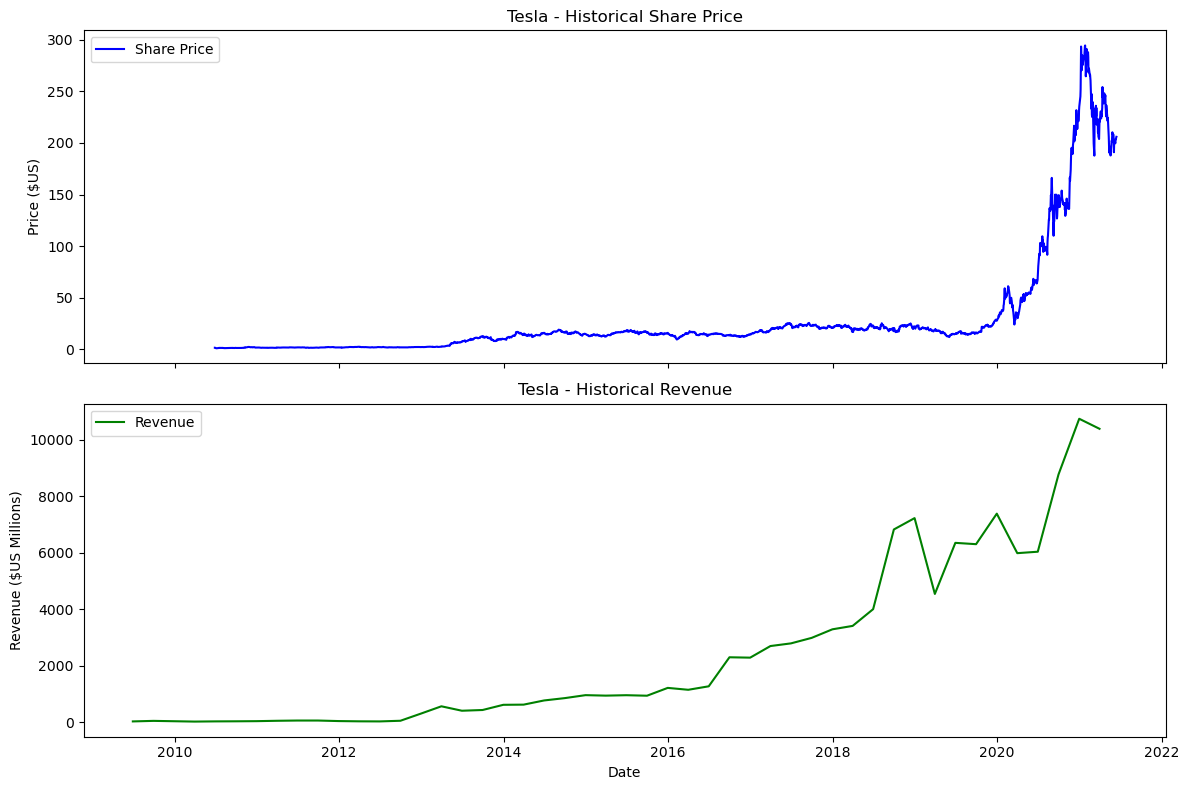

In [24]:
import pandas as pd
import matplotlib.pyplot as plt


def make_graph(tesla_data, tesla_revenue, tesla):
    
    
    tesla_data['Date'] = pd.to_datetime(tesla_data['Date'])
    tesla_revenue['Date'] = pd.to_datetime(tesla_revenue['Date'])
    
    tesla_data['Close'] = tesla_data['Close'].astype(float)
    tesla_revenue['Revenue'] = tesla_revenue['Revenue'].astype(float)
    
    
    stock_data_specific = tesla_data[tesla_data.Date <= '2021-06-14']
    revenue_data_specific = tesla_revenue[tesla_revenue.Date <= '2021-04-30']

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)


    axes[0].plot(stock_data_specific.Date, stock_data_specific.Close, label="Share Price", color="blue")
    axes[0].set_ylabel("Price ($US)")
    axes[0].set_title(f"{tesla} - Historical Share Price")
    axes[0].legend()

    axes[1].plot(revenue_data_specific.Date, revenue_data_specific.Revenue, label="Revenue", color="green")
    axes[1].set_ylabel("Revenue ($US Millions)")
    axes[1].set_xlabel("Date")
    axes[1].set_title(f"{tesla} - Historical Revenue")
    axes[1].legend()

    plt.tight_layout()
    plt.show()
    
make_graph(tesla_data, tesla_revenue, 'Tesla')

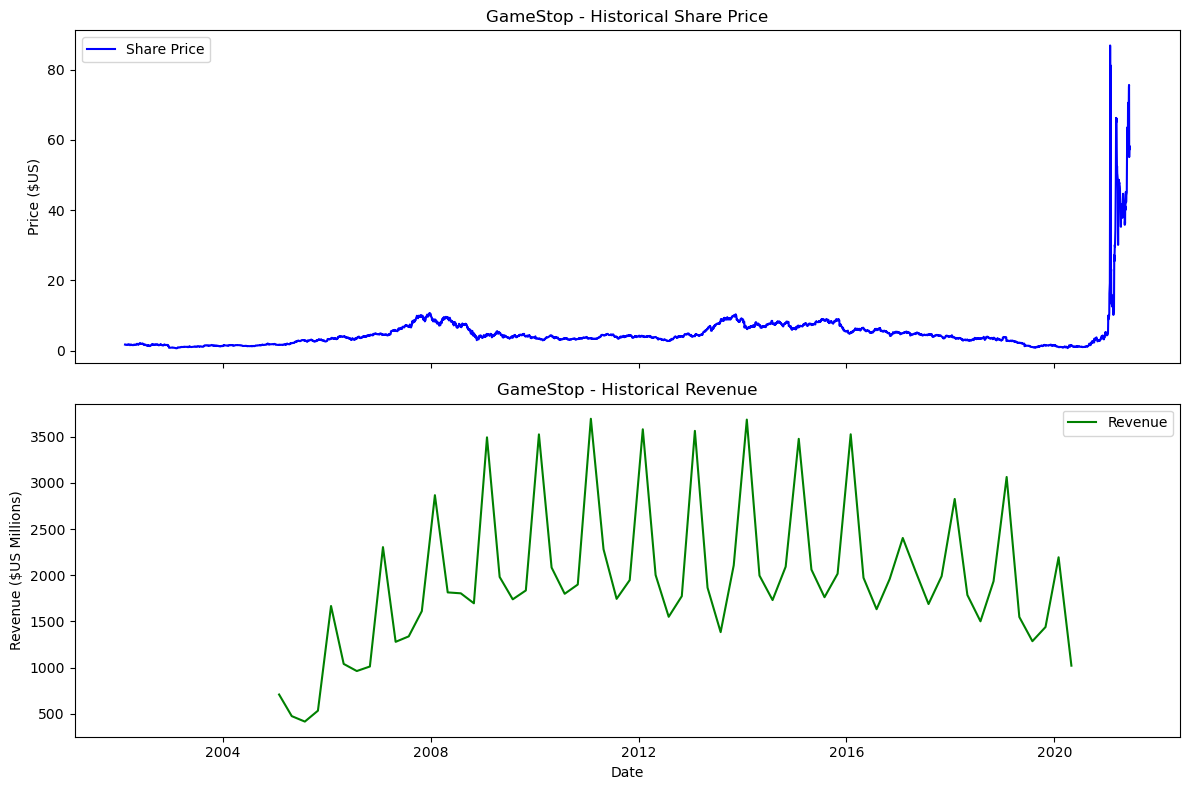

In [26]:
make_graph(gamestop_data, gme_revenue, 'GameStop')